In [1]:
%load_ext autoreload
%autoreload 2

In [102]:
import importlib
import dataset_creation.pre_process

importlib.reload(dataset_creation.pre_process)  # Reload the module

<module 'dataset_creation.pre_process' from 'C:\\Users\\danie\\Desktop\\Thesis_Experiment\\Thesis_repo\\Multi-Hop-Knowledge-Conflicts\\dataset_creation\\pre_process.py'>

1. Summarize shortly each of the 6 candidate datasets and choose the right ones.
2. Structure them as question-answer pairs (with aliases if needed).
3. Remove ambiguous questions.
4. Add classification for the answer type (wikipedia entity, number or date).
5. Rephrase question if needed.
6. Find crucial entity.
7. Add definitions from WikiData and create embedding using sentence bert based model.
8. Create a way to find similar answers (different rules for each type of answer).
9. Create triplets.

---> I can try to understand if an entity is crucial through the answer paragraph (if not than it probably wont be there).

# Functions:

In [2]:
# Load data from memory:

import json
def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)  # Parse JSON and return as a dictionary

# Example usage
data = load_json("triviaqa_train.json")

In [33]:
# Check if an entity is a number:

def is_convertible_to_int(ent):
    try:
        return isinstance(int(ent), int)
    except ValueError:
        return False

In [32]:
# Calculate sentence similarity:

from sentence_transformers import SentenceTransformer, util

# Load pre-trained Sentence-BERT model
model = SentenceTransformer('all-MiniLM-L6-v2')  # You can choose another model as well

def sentence_similarity(sent1, sent2):
    """
    Compute cosine similarity between two sentences using Sentence-BERT.
    
    Args:
    - sent1: First sentence
    - sent2: Second sentence
    
    Returns:
    - Similarity score (float)
    """
    # Encode sentences to embeddings
    embedding1 = model.encode(sent1, convert_to_tensor=True)
    embedding2 = model.encode(sent2, convert_to_tensor=True)
    
    # Compute cosine similarity between the two sentence embeddings
    similarity = util.pytorch_cos_sim(embedding1, embedding2)
    
    return similarity.item()

C:\Users\danie\Desktop\Thesis_Experiment\Thesis_repo\Multi-Hop-Knowledge-Conflicts\dev_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [51]:
# get a question with the same answer with distant similarity score:

def get_question(question, answer, data, threshold=0.4):
    for sample in data:
        if sample['Answer'] == answer:
            if sentence_similarity(sample['Question'], question) < threshold:
                return sample['Question']

In [37]:
# Check if an article exist by title:

import wikipediaapi
import wikipedia

def article_exists(title, lang="en"):
    wiki_wiki = wikipediaapi.Wikipedia(user_agent='your-user-agent', language=lang)  # Set language (default is English)
    page = wiki_wiki.page(title)
    return page.exists()  # Returns True if the page exists, False otherwise

def article_exists_partial(title, lang="en"):
    # Initialize Wikipedia API with the given language
    wiki_wiki = wikipediaapi.Wikipedia(user_agent='your-user-agent', language=lang)

    # Use Wikipedia's search function to find related pages
    search_results = wikipedia.search(title, results=10, suggestion=False)

    # Filter out the exact match and keep only partial matches
    partial_matches = [result for result in search_results if title.lower() in result.lower() and result.lower() != title.lower()]

    return len(partial_matches) > 0  # Return True if there's at least one partial match

# Inference:

### Create base Q-A pairs:

In [7]:
from dataset_creation.get_datasets import get_datasets

data = get_datasets()

Loading TriviaQA JSON file: 100%|███████████████████████████████████████████████| 2.41G/2.41G [33:22<00:00, 1.21MB/s]
Extracting TriviaQA dataset QA pairs: 100%|████████████████████████████████| 87622/87622 [00:00<00:00, 783396.65it/s]

Collected 74616 QA pairs from 1 available datasets.


In [10]:
output_file_path = "triviaqa_train.json"  # Path to save the file

# Save the data to a JSON file
with open(output_file_path, "w", encoding="utf-8") as output_file:
    json.dump(data, output_file, ensure_ascii=False, indent=4)

print(f"JSON saved to {output_file_path}")

JSON saved to triviaqa_train.json


### Show how many duplicate answers are in the train set:

100%|██████████████████████████████████████████████████████████████████████████| 74616/74616 [17:17<00:00, 71.89it/s]


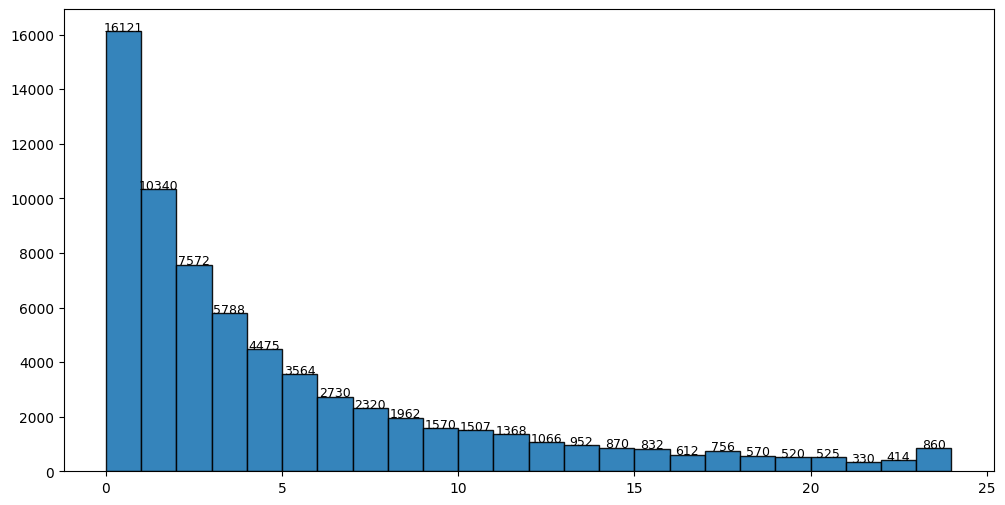

In [9]:
import matplotlib.pyplot as plt

%matplotlib inline

def how_many(ans, dataset):
    num = 0
    for sample in dataset:
        if sample['Answer'] == ans:
            num += 1
    return num - 1

def hist_dups(dataset):
    values = []
    for sample in tqdm(dataset):
        ans = sample['Answer']
        values.append(how_many(ans, dataset))

    fig, ax = plt.subplots(figsize=(12,6))
    counts, bins, patches = ax.hist(values, bins=range(0,25), edgecolor="black", alpha=0.9)
    # Annotate each bar with its count
    for count, bin_edge in zip(counts, bins[:-1]):  # Exclude the last bin edge
        ax.text(bin_edge + 0.5, count + 0.5, str(int(count)), ha="center", fontsize=9)
    plt.show()


hist_dups(data)

In [14]:
answer_appears = {}
for sample in tqdm(data):
    answer = sample['Answer']
    if answer not in answer_appears:
        answer_appears[answer] = how_many(answer, data)

100%|█████████████████████████████████████████████████████████████████████████| 74616/74616 [07:32<00:00, 165.02it/s]


In [18]:
sorted_data = dict(sorted(answer_appears.items(), key=lambda item: item[1], reverse=True))

sorted_data

{'Australia': 152,
 'France': 132,
 'New Zealand': 113,
 'Spain': 101,
 'Italy': 99,
 'South Africa': 99,
 'Canada': 98,
 'United States': 93,
 'Brazil': 92,
 'India': 89,
 'Switzerland': 88,
 'Argentina': 85,
 'Denmark': 85,
 'Japan': 84,
 'Germany': 84,
 'China': 81,
 'Portugal': 78,
 'Egypt': 69,
 'Belgium': 69,
 'New York': 69,
 'Russia': 69,
 'Red': 68,
 'Sweden': 65,
 'Fish': 65,
 'Turkey': 65,
 'Poland': 64,
 'Mexico': 64,
 'Green': 59,
 'Bird': 58,
 'Greece': 57,
 'Chile': 57,
 'Blue': 56,
 'Chicago': 55,
 'Paris': 55,
 'Dog': 55,
 'Norway': 53,
 'Austria': 53,
 'Yellow': 53,
 'London': 53,
 'Winston Churchill': 53,
 'Finland': 51,
 'Golf': 51,
 'Apple': 51,
 'Ireland': 50,
 'Hawaii': 50,
 'California': 50,
 'Netherlands': 49,
 'Iceland': 48,
 'Jupiter': 47,
 'Alaska': 46,
 'Uranus': 45,
 'Theodore Roosevelt': 45,
 'Cheese': 45,
 'Thailand': 44,
 'Hungary': 43,
 'Eye': 43,
 'Cat': 42,
 'Glasgow': 42,
 'Boxing': 41,
 'Indonesia': 41,
 'Cricket': 41,
 'Horse': 41,
 'Cyprus': 41,


### Extract entities from questions:

In [72]:
from dataset_creation.pre_process import extract_ent
import numpy as np

for i in range(10):
    print('Question:')
    print(f"{data[i]['Question']} ---> {data[i]['Answer']}")

    print('Entities:')
    ents = extract_ent(data[i]['Question'])
    num_in_data = [how_many(ent, data) + 1 for ent in ents]
    summary = {}
    for ent, num in zip(ents, num_in_data):
        if num > 0:
            summary[ent] = num
    print(summary)

    for idx, sample in enumerate(summary.items()):
        print(f'Question example {idx}:')
        new_question = get_question(data[i]['Question'], sample[0], data)
        print(f"Question: {new_question} ---> {sample[0]}")
        print(f"Similarity score: {sentence_similarity(new_question, data[i]['Question'])}")
        
    print('=' * 100)

Question:
Who was President when the first Peanuts cartoon was published? ---> Harry S. Truman
Entities:
{'President': 1}
Question example 0:
Question: The Head of State in Italy is (at 2011) a? ---> President
Similarity score: 0.08240306377410889
Question:
Which American-born Sinclair won the Nobel Prize for Literature in 1930? ---> Sinclair Lewis
Entities:
{'Nobel Prize': 2, 'Literature': 6}
Question example 0:
Question: Which annual prizes were established by the legacy of a Swedish chemist? ---> Nobel Prize
Similarity score: 0.3363964259624481
Question example 1:
Question: In 1973, Patrick White became the first Australian to win a Nobel Prize in what? ---> Literature
Similarity score: 0.36605915427207947
Question:
Where in England was Dame Judi Dench born? ---> York
Entities:
{'England': 29}
Question example 0:
Question: In which country is My Fair Lady set? ---> England
Similarity score: 0.28982529044151306
Question:
In which decade did Billboard magazine first publish and Americ

In [135]:
from dataset_creation.pre_process import extract_ent, validate_ent, check_if_crucial, check_interpretation
import numpy as np

total_num = 20
relevant_num = 0

for i in range(total_num):
    print('Question:')
    print(f"{data[i]['Question']} ---> {data[i]['Answer']}")

    print('Entities:')
    extracted_ents = extract_ent(data[i]['Question'])

    crucial_ents = []
    for ent in extracted_ents:
        if check_if_crucial(data[i]['Question'], ent) and article_exists(ent) and (not(check_interpretation(ent)) or is_convertible_to_int(ent)):
            crucial_ents.append(ent)
        
    print(crucial_ents)

    if len(crucial_ents) > 0:
        relevant_num += 1
        
    print('=' * 100)

print(f'{relevant_num} out of {total_num}')

Question:
Who was President when the first Peanuts cartoon was published? ---> Harry S. Truman
Entities:
[]
Question:
Which American-born Sinclair won the Nobel Prize for Literature in 1930? ---> Sinclair Lewis
Entities:
['Nobel Prize for Literature', '1930']
Question:
Where in England was Dame Judi Dench born? ---> York
Entities:
['England', 'Dame Judi Dench']
Question:
In which decade did Billboard magazine first publish and American hit chart? ---> 30s
Entities:
['Billboard magazine']
Question:
From which country did Angola achieve independence in 1975? ---> Portugal
Entities:
['Angola', '1975']
Question:
Which city does David Soul come from? ---> Chicago
Entities:
['David Soul']
Question:
Who won Super Bowl XX? ---> Chicago Bears
Entities:
['Super Bowl XX']
Question:
Which was the first European country to abolish capital punishment? ---> Norway
Entities:
['capital punishment']
Question:
In which country did he widespread use of ISDN begin in 1988? ---> Japan
Entities:
['1988']
Que

In [41]:
from dataset_creation.pre_process import extract_ent, validate_ent, check_if_crucial
import numpy as np

forbidden_list = ['Who', 'What', 'Which', 'Was', 'Why', 'When']

total_num = 100
relevant_num = 0

data_with_ents = []

for i in range(total_num):
    print('Question:')
    print(f"{data[i]['Question']} ---> {data[i]['Answer']}")

    print('Entities:')
    ents = set()
    extracted_ents = extract_ent(data[i]['Question'])
    for sample in data:
        if sample['Answer'] in extracted_ents and sample['Answer'] not in forbidden_list and len(sample['Answer']) > 2:
            if sentence_similarity(sample['Question'], data[i]['Question']) < 0.4:
                ents.add(sample['Answer'])
                print(f"{sample['Answer']} --- > {sample['Question']}")
                print()
    new_ents = []
    for ent in ents:
        ents.remove(ent)
        if not any([ent in other for other in ents]):
            new_ents.append(ent)
        ents.add(ent)

    crucial_ents = []
    for ent in new_ents:
        if check_if_crucial(data[i]['Question'], ent): # and article_exists(ent):
            crucial_ents.append(ent)
        
    print(crucial_ents)

    if len(crucial_ents) > 0:
        relevant_num += 1
        data_with_ents.append(data[i].copy())
        data_with_ents[-1]['Entities'] = crucial_ents
        
    print('=' * 100)

print(f'{relevant_num} out of {total_num}')

Question:
Who was President when the first Peanuts cartoon was published? ---> Harry S. Truman
Entities:
President --- > The Head of State in Italy is (at 2011) a?

Peanuts --- > What crop was farmed by Jimmy Carter?

Peanuts --- > The names of the command module and lunar module of Apollo 10 were named for the characters of what story that was told in nearly 18,000 strips?

Peanuts --- > Which nuts are used to make satay sauce?

Peanuts --- > Feb 13, 2000 saw the last original installment of what comic strip, following the death of its creator, Charles Shultz?

Peanuts --- > In addition to documenting 118 uses for sweet potatoes, inventor/scientist George Washington Carver discovered more than 300 uses for what crop?

Peanuts --- > The Hershey's confection known as Mr. Goodbar is a mixture of chocolate and what other ingredient?

Peanuts --- > October 2, 1950 saw the debut of what comic strip which ran until creator Charles M. Schulz's death on Feb 12, 2000?

['Peanuts', 'President']


In [143]:
data_with_ents

[{'Question': 'Who was President when the first Peanuts cartoon was published?',
  'Answer': 'Harry S. Truman',
  'Entities': ['Peanuts', 'President']},
 {'Question': 'Where in England was Dame Judi Dench born?',
  'Answer': 'York',
  'Entities': ['England']},
 {'Question': 'From which country did Angola achieve independence in 1975?',
  'Answer': 'Portugal',
  'Entities': ['Angola']},
 {'Question': 'Which city does David Soul come from?',
  'Answer': 'Chicago',
  'Entities': ['David Soul']},
 {'Question': 'In which country did he widespread use of ISDN begin in 1988?',
  'Answer': 'Japan',
  'Entities': ['1988']},
 {'Question': "What is Bruce Willis' real first name?",
  'Answer': 'Walter',
  'Entities': ['Bruce Willis']},
 {'Question': 'Which William wrote the novel Lord Of The Flies?',
  'Answer': 'Golding',
  'Entities': ['William Golding']},
 {'Question': "Which country is Europe's largest silk producer?",
  'Answer': 'Italy',
  'Entities': ['Europe']},
 {'Question': 'At which uni

### Extract dataset answer's definitions from wikipedia:

In [48]:
import requests

def get_wikidata_description(entity, lang="en"):
    url = f"https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbsearchentities",
        "search": entity,
        "language": lang,
        "format": "json",
        "limit": 1
    }

    response = requests.get(url, params=params)
    data = response.json()

    if "search" in data and len(data["search"]) > 0:
        return data["search"][0].get("description", "No description available.")
    else:
        return f"No Wikidata entry found for '{entity}'."

# Example usage
entity = "Albert Einstein"
description = get_wikidata_description(entity)
print(description)

German-born theoretical physicist (1879–1955)


In [149]:
# Example:
for sample in data_with_ents:
    for ent in sample['Entities']:
        print(f"{ent} - {get_wikidata_description(ent)}")

Peanuts - legume cultivated as a grain and oiled up crop
President - leader of a country or part of a country, usually in republics
England - country in north-west Europe, part of the United Kingdom
Angola - country on the west coast of Southern Africa
David Soul - American-British actor (1943–2024)
1988 - year
Bruce Willis - American actor (born 1955)
William Golding - British novelist, poet, playwright and Nobel Prize for Literature laureate (1911–1993)
Europe - continent in the Northern Hemisphere
Joseph Goebbels - Nazi politician and Propaganda Minister (1897–1945)
Algeria - country in North Africa
Michael Caine - English actor (born 1933)
Belize - sovereign state in Central America
La Dolce Vita - 2017 song by Lacrim
2001: A Space Odyssey - 1968 film by Stanley Kubrick
Ezzard Charles - American boxer (1921–1975)
Billy Crystal - American actor and comedian
George - male given name
Chinese - language group of the Sinitic languages
Kevin Kline - American actor
Doberman Pinscher - Ger

In [16]:
import aiohttp
import asyncio
import random
import nest_asyncio
from tqdm.asyncio import tqdm_asyncio  

# Set max concurrent requests
MAX_CONCURRENT_REQUESTS = 20  
answer_desc_global = {}  # Global dictionary to store results

async def get_wikidata_description_async(entity, session, semaphore, lang="en", max_retries=3):
    """Fetch a short description from Wikidata with controlled concurrency."""
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbsearchentities",
        "search": entity,
        "language": lang,
        "format": "json",
        "limit": 1
    }
    headers = {"User-Agent": "YourAppName/1.0 (your-email@example.com)"}  

    async with semaphore:  # Limit concurrent requests
        for attempt in range(max_retries):
            try:
                async with session.get(url, params=params, headers=headers) as response:
                    if response.status == 429:
                        retry_after = int(response.headers.get("Retry-After", random.uniform(2, 5)))  
                        print(f"Rate limited. Retrying in {retry_after} seconds...")
                        await asyncio.sleep(retry_after)
                        continue  

                    data = await response.json()
                    if "search" in data and len(data["search"]) > 0:
                        return data["search"][0].get("description", "No description available.")
                    return f"No Wikidata entry found for '{entity}'."
            
            except aiohttp.ClientError as e:
                print(f"Request failed: {e}. Retrying in {2**attempt} seconds...")
                await asyncio.sleep(2**attempt)  

    return f"Failed to fetch description for '{entity}' after {max_retries} retries."

async def answer_descriptions_async(data, max_concurrent=MAX_CONCURRENT_REQUESTS):
    """Fetch descriptions for multiple entities asynchronously with controlled concurrency."""
    global answer_desc_global  # Use the global variable
    answer_desc_global = {}  # Reset the dictionary

    semaphore = asyncio.Semaphore(max_concurrent)  # Limit concurrent requests

    async with aiohttp.ClientSession() as session:
        tasks = [
            get_wikidata_description_async(sample['Answer'], session, semaphore) for sample in data
        ]
        results = await tqdm_asyncio.gather(*tasks)  

        for sample, description in zip(data, results):
            answer_desc_global[sample['Answer']] = description  # Store in global variable

    return answer_desc_global  # Also return it for immediate use

# Example usage
async def main():
    
    await answer_descriptions_async(data, max_concurrent=3)  # Limit to 3 concurrent requests

# Run the async function
nest_asyncio.apply()

await main()  # Use 'await' in Jupyter Notebook

# The output is now stored in `answer_desc_global` and can be used in later cells

100%|████████████████████████████████████████████████████████████████████████| 74616/74616 [1:41:37<00:00, 12.24it/s]


In [19]:
answer_desc_global

{'Harry S. Truman': 'president of the United States from 1945 to 1953; politician (1884-1972)',
 'Sinclair Lewis': 'American writer and playwright (1885–1951)',
 'York': 'family name',
 '30s': 'decade',
 'Portugal': 'country in Southwestern Europe',
 'Chicago': 'city and county seat of Cook County, Illinois, United States of America',
 'Chicago Bears': 'American football team',
 'Norway': 'country in Northern Europe',
 'Japan': 'island country in East Asia',
 'Walter': 'male given name',
 'Golding': 'family name',
 'Windscreen wiper': 'device on vehicle',
 'Big Bill Broonzy': 'American blues singer, songwriter and guitarist (1893–1958)',
 'Joan Rivers': 'American comedian, actress, and television host (1933–2014)',
 'Ballet': 'type of performance dance; performing arts genre; theatrical genre',
 'Italy': 'country in Southern Europe',
 'Helicopter': 'type of rotor craft in which lift and thrust are supplied by rotors',
 'Heidelberg': 'large city in Baden-Württemberg, Germany',
 'Edward'

In [18]:
output_file_path = "answer_wiki_definition.json"  # Path to save the file

# Save the data to a JSON file
with open(output_file_path, "w", encoding="utf-8") as output_file:
    json.dump(answer_desc_global, output_file, ensure_ascii=False, indent=4)

print(f"JSON saved to {output_file_path}")

JSON saved to answer_wiki_definition.json


### Definitions embedding and searchin for closest answer:

In [23]:
from sentence_transformers import SentenceTransformer
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Load the SBERT model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Step 1: Encode all sentences into vectors
wikipedia_definition_sentences = [f'{key} - {value}' for key, value in answer_desc_global.items()]
sentence_embeddings = model.encode(wikipedia_definition_sentences, convert_to_numpy=True)

In [29]:
# Step 2: Define a function to find the most similar sentence (excluding exact match)
def find_most_similar(query, exclude_exact_match=False, similarity_range=(0.5, 0.6)):
    query_embedding = model.encode([query], convert_to_numpy=True)
    similarities = cosine_similarity(query_embedding, sentence_embeddings)[0]

    # Get indices sorted by similarity (descending)
    sorted_indices = np.argsort(similarities)[::-1]

    for idx in sorted_indices:
        if exclude_exact_match:
            if wikipedia_definition_sentences[idx] != query:  # Exclude exact match
                if similarities[idx] >= similarity_range[0] and similarities[idx] <= similarity_range[1]:
                    return wikipedia_definition_sentences[idx], similarities[idx]
        else:
            if similarities[idx] >= similarity_range[0] and similarities[idx] <= similarity_range[1]:
                return wikipedia_definition_sentences[idx], similarities[idx]

In [30]:
# Example query
query_sentence = "Albert Einstein - German-born theoretical physicist (1879–1955)"
best_match, similarity_score = find_most_similar(query_sentence, exclude_exact_match=True)

print(f"Query: {query_sentence}")
print(f"Best Match (not the same): {best_match}")
print(f"Similarity Score: {similarity_score:.4f}")

Query: Albert Einstein - German-born theoretical physicist (1879–1955)
Best Match (not the same): Thomas Kuhn - American historian, physicist and philosopher
Similarity Score: 0.5941


### Pipeline testing:

In [42]:
data_with_ents

[{'Question': 'Who was President when the first Peanuts cartoon was published?',
  'Answer': 'Harry S. Truman',
  'Entities': ['Peanuts', 'President']},
 {'Question': 'Where in England was Dame Judi Dench born?',
  'Answer': 'York',
  'Entities': ['England']},
 {'Question': 'From which country did Angola achieve independence in 1975?',
  'Answer': 'Portugal',
  'Entities': ['Angola']},
 {'Question': 'Which city does David Soul come from?',
  'Answer': 'Chicago',
  'Entities': ['David Soul']},
 {'Question': 'In which country did he widespread use of ISDN begin in 1988?',
  'Answer': 'Japan',
  'Entities': ['1988']},
 {'Question': "What is Bruce Willis' real first name?",
  'Answer': 'Walter',
  'Entities': ['Bruce Willis']},
 {'Question': 'Which William wrote the novel Lord Of The Flies?',
  'Answer': 'Golding',
  'Entities': ['William']},
 {'Question': "Which country is Europe's largest silk producer?",
  'Answer': 'Italy',
  'Entities': ['Europe']},
 {'Question': 'At which university 

In [71]:
import random

def print_tree(sample):
    right_leaf = get_question(sample['Question'], sample['Answer'], data)
    
    example_entity_def = get_wikidata_description(sample['Entities'][0], lang="en")
    example_entity_query = f"{sample['Entities'][0]} - {example_entity_def}"
    best_match, similarity_score = find_most_similar(example_entity_query, exclude_exact_match=True)
    best_match_ent = best_match.split(' - ')[0]
    left_leaf = get_question(sample['Question'], best_match_ent, data, threshold=1)


    first_question_counter_answers = generate_counter_answers(sample['Question'], sample['Answer'])
    right_question_counter_answers = generate_counter_answers(right_leaf, sample['Answer'])

    final_counter_answer = None
    
    for answer1, answer2 in zip(first_question_counter_answers, right_question_counter_answers):
        if answer1 == answer2:
            final_counter_answer = answer1
            break

    if final_counter_answer == None:
        final_counter_answer = random.choice(first_question_counter_answers)
    
    # Print summary:
    print(f"Main Question: ")
    print(f"{sample['Question']}")
    print()
    print(f"Main Answer: ")
    print(f"{sample['Answer']}")
    print()
    print(f"Question with the same answer: ")
    print(f"{right_leaf}")
    print()
    print(f"Counter answer for both: ")
    print(f"{final_counter_answer}")
    print()
    print(f"Question that can be linked to the following entity in the question: {example_entity_query}")
    print(f"{left_leaf}")
    print(f"True answer: {best_match}")

In [118]:
print_tree(data_with_ents[5])

Main Question: 
What is Bruce Willis' real first name?

Main Answer: 
Walter

Question with the same answer: 
What was the forename of Mr. Bentley, founder of the famous car company?

Counter answer for both: 
His real first name is Robert.

Question that can be linked to the following entity in the question: Bruce Willis - American actor (born 1955)
In the 1989 film, who was Driving Miss Daisy?
True answer: Morgan Freeman - American actor and producer (born 1937)


In [116]:
from dataset_creation.pre_process import extract_question_structure

for sample in data_with_ents:
    print(sample['Question'])
    question_components = json.loads(extract_question_structure(sample['Question']))
    crucial_ents = []
    for comp in question_components.values():
        if len(extract_ent(comp)) > 0:
            crucial_ents.append(comp)
    print(crucial_ents)

Who was President when the first Peanuts cartoon was published?
['President']
Where in England was Dame Judi Dench born?
['Dame Judi Dench']
From which country did Angola achieve independence in 1975?
['Angola', 'achieve independence', 'country']
Which city does David Soul come from?
['David Soul', 'come from']
In which country did he widespread use of ISDN begin in 1988?
['widespread use of ISDN']
What is Bruce Willis' real first name?
['Bruce Willis', 'real first name']
Which William wrote the novel Lord Of The Flies?
['William', 'the novel Lord Of The Flies']
Which country is Europe's largest silk producer?
['country', "Europe's largest silk producer"]
At which university did Joseph Goebbels become a doctor of philosophy?
['Joseph Goebbels', 'a doctor of philosophy']
What are the international registration letters of a vehicle from Algeria?
['the international registration letters of a vehicle from Algeria']
What star sign is Michael Caine?
['Michael Caine', 'star sign']
What are th

KeyboardInterrupt: 

### Subject and object:

In [120]:
import spacy

# Load spaCy's English model with dependency parsing and NER
nlp = spacy.load("en_core_web_sm")

# Common question words that shouldn't be treated as subjects
QUESTION_WORDS = {"who", "what", "where", "when", "why", "how", "which"}

def extract_subject_object(question):
    doc = nlp(question)
    subject = None
    objects = []

    for token in doc:
        # Identify subject but filter out question words
        if "subj" in token.dep_ and token.text.lower() not in QUESTION_WORDS:
            subject = token.text

        # Identify objects that are named entities
        if "obj" in token.dep_:
            if any(ent.text == token.text for ent in doc.ents):
                objects.append(token.text)

    # If no subject is found, assume the answer is the subject
    if subject is None and objects:
        subject = objects.pop(0)  # Take the first entity object as subject

    return {"subject": subject, "objects": objects}

In [121]:
for sample in data_with_ents:
    print(f"Question: {sample['Question']}")
    print(extract_subject_object(sample['Question']))
    print('===================')

Question: Who was President when the first Peanuts cartoon was published?
{'subject': 'cartoon', 'objects': []}
Question: Where in England was Dame Judi Dench born?
{'subject': 'Dench', 'objects': ['England']}
Question: From which country did Angola achieve independence in 1975?
{'subject': 'Angola', 'objects': ['1975']}
Question: Which city does David Soul come from?
{'subject': 'Soul', 'objects': []}
Question: In which country did he widespread use of ISDN begin in 1988?
{'subject': 'use', 'objects': ['ISDN', '1988']}
Question: What is Bruce Willis' real first name?
{'subject': 'name', 'objects': []}
Question: Which William wrote the novel Lord Of The Flies?
{'subject': 'William', 'objects': []}
Question: Which country is Europe's largest silk producer?
{'subject': 'country', 'objects': []}
Question: At which university did Joseph Goebbels become a doctor of philosophy?
{'subject': 'Goebbels', 'objects': []}
Question: What are the international registration letters of a vehicle from 

### Replace with _____

In [122]:
def replace_word(sentence, word_to_replace):
    """
    Replaces the first occurrence of a word in a sentence with '_____'.
    
    Args:
        sentence (str): The input sentence.
        word_to_replace (str): The word to be replaced.

    Returns:
        str: The sentence with the word replaced.
    """
    return sentence.replace(word_to_replace, "_____", 1)  # Replace only the first occurrence

In [126]:
from dataset_creation.pre_process import determine_crucial

for sample in data_with_ents:
    print(sample['Question'])
    valid_ents = []
    for ent in sample['Entities']:
        verd = determine_crucial(replace_word(sample['Question'], ent))
        print(f"{ent} --> {replace_word(sample['Question'], ent)} --> {verd}")
        if verd:
            valid_ents.append(ent)
    print(valid_ents)
    print('==============')

Who was President when the first Peanuts cartoon was published?
Peanuts --> Who was President when the first _____ cartoon was published? --> True
President --> Who was _____ when the first Peanuts cartoon was published? --> False
['Peanuts']
Where in England was Dame Judi Dench born?
England --> Where in _____ was Dame Judi Dench born? --> True
['England']
From which country did Angola achieve independence in 1975?
Angola --> From which country did _____ achieve independence in 1975? --> False
[]
Which city does David Soul come from?
David Soul --> Which city does _____ come from? --> True
['David Soul']
In which country did he widespread use of ISDN begin in 1988?
1988 --> In which country did he widespread use of ISDN begin in _____? --> True
['1988']
What is Bruce Willis' real first name?
Bruce Willis --> What is _____' real first name? --> True
['Bruce Willis']
Which William wrote the novel Lord Of The Flies?
William --> Which _____ wrote the novel Lord Of The Flies? --> True
['Wi

# Steps for entity extraction:
1. Get candidates:
    - For every question, search for all answers in the dataset that appear in the question.
    - Remove a candidate in the list that is a part of another candidate (e.g., george < george bush).
2. Test if crucial:
    - Create 'Blank' verson of the question without the candidate.
    - Let a model answer the question with and without the blank, let it the option to return the question is ambiguous.

In [5]:
from random import choices
dev_data = choices(data, k=10)

In [30]:
from dataset_creation.entity_extraction import get_candidate_entities, remove_ent_duplicates, frame_entity, replace_word, fill_the_blanks, answer_question, shared_words_percentage
from tqdm import tqdm

for sample in tqdm(dev_data[0:1]):
    print(f"{sample['Question']} --> {sample['Answer']}")
    candidate_entities = get_candidate_entities(sample['Question'], dataset=data)
    clean_candidate_entities = remove_ent_duplicates(candidate_entities)
    print(clean_candidate_entities)
    framed_ents = []
    for ent in clean_candidate_entities:
        framed_ents.append(frame_entity(sample['Question'], ent))
    ent_spans = remove_ent_duplicates(framed_ents)
    for ent in ent_spans:
        masked_sentence = replace_word(sample['Question'], ent)
        replacement = fill_the_blanks(masked_sentence)
        shared = shared_words_percentage(replacement, ent)
        print(f'{ent} <--> {replacement} ----> {shared}')
        if shared < 0.5:
            final_ent = ent
            break
            
    print(final_ent)
    print(20 * '=')

  0%|                                                                                            | 0/1 [00:00<?, ?it/s]

Jean-Claude Van Damme plays both of the twins, separated after the death of their parents, in which 1991 film? --> Double Impact
['1991']


100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.71s/it]

the twins, separated after the death of their parents, in which 1991 film <--> his characters in the movie "Double Impact" ----> 0.11764705882352941
the twins, separated after the death of their parents, in which 1991 film


1. Check for random 10 samples each time - that way I'll know it's robust
2. Use asincio for multiple requests
3. Create a batch of sentences to create - make it faster and will not surpass the request limit
4. Make output be only the strart-end sequencials of the phrase - less tokens as output so well set the token output and not surpass the token limit

In [6]:
from dataset_creation.entity_extraction import entity_extraction

# Example usage
for sample in choices(data, k=10):
    question = sample['Question']
    print(question)
    list_words = question.split()
    for index in entity_extraction(question):
        print(index)
        # start = index[0]
        # end = index[1]
        # print(start, end)
        break
        print(list_words[start:end], end=' | ')
    print()

In 1956, which country became the first Islamic republic in the world?

What serial killer, who buried the remains of 26 of his victims in his Chicago crawl space, was known as the "Killer Clown"?
(66, 72)

In which war film is John Wayne's character killed by a Japanese sniper?
(26, 26)

On a QWERTY keyboard the backslash (\) shares the key with the?

Which English monarch was the son of Edmund Tudor, 1st Earl of Richmond?

Somaliland and Eritrea were both colonized by which European nation?
(0, 0)

On TV, if Pete Waterman was the Hitman, who was Her ?
(3, 5)

What country imports river sand from Scotland for construction and camels from North Africa
(39, 45)

Which is the only remaining women's college in Oxford University?

"Whose famous books include ""The Descent of Man, and Selection in Relation to Sex"", ""The Expression of Emotions in Man and Animals"", "" The Power of Movement in Plants"" and ""The Formation of Vegetable Mould Through the Action of Worms""?"



In [12]:
import importlib
import dataset_creation.pre_process

importlib.reload(dataset_creation.api_tools)  # Reload the module

<module 'dataset_creation.api_tools' from 'C:\\Users\\danie\\Desktop\\Thesis_Experiment\\Thesis_repo\\Multi-Hop-Knowledge-Conflicts\\dataset_creation\\api_tools.py'>

In [4]:
from dataset_creation.api_tools import gpt_api
import asyncio
import nest_asyncio
from random import choices
from tqdm import tqdm
nest_asyncio.apply()  # Enables asyncio.run() inside Jupyter
import time

gpt = gpt_api(system_prompt="answer the following question in no more than 3 words.", max_concurrent_requests=25)
queries = [sample['Question'] for sample in choices(data, k=100)]

# # Single synchronous call
# start_time = time.time()
# responses = []
# for quer in tqdm(queries):
#     responses.append(gpt.run(quer))
# end_time = time.time()
# print(responses)
# print('=' * 100)
# print(end_time - start_time)
# print('=' * 100)

# Multiple async calls
start_time = time.time()
responses = asyncio.run(gpt.async_run(queries))
end_time = time.time()
print(responses)
print('=' * 100)
print(end_time - start_time)
print('=' * 100)

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [00:08<00:00, 11.73it/s]

['Tom Wolfe', 'Christopher Columbus', 'Hemorrhoids', 'Guru Granth Sahib', 'Thomas the Tank Engine', 'The Bronx', 'Asparagus', 'Charles Darwin', 'Henry VI, Part 1', 'Kevin Smith', 'Lateral Sclerosis', 'Caernarfon Castle', 'John Smith', 'Herbert Hoover', 'Queen Elizabeth I', 'Deportivo La Coruña', 'Georgia', 'Dartmoor', 'Liverpool FC', 'HMS Invincible', 'Mark Twain', 'Santa Fe', 'Airdrieonians FC', 'John Masefield', 'Goodluck Jonathan', 'Soy sauce', 'War of Austrian Succession', 'St. Pancras', 'Guy Pearce', 'Malt vinegar', 'Diphthong', 'USS Nautilus', 'Mexico', 'Jacques Chirac', 'Te Awamutu, New Zealand', 'Virgo', 'Switzerland, Gotthard Base', 'Lizards', 'Fiddler on the Roof', 'Philippi, Macedonia', 'Black dog', 'Grayson Perry', 'Sir Francis Drake', 'Northern pike', 'United Kingdom', 'Salt', 'The Washington Times', 'Tyson Fury', 'Panda bear', 'BZ', 'Graces (Charites)', 'Ian Rush', 'Ode to Autumn', 'University of London', 'The Lord of the Rings: The Return of the King', 'True statement.',

In [140]:
import importlib
import dataset_creation.entity_extraction

importlib.reload(dataset_creation.entity_extraction)  # Reload the module

<module 'dataset_creation.entity_extraction' from 'C:\\Users\\danie\\Desktop\\Thesis_Experiment\\Thesis_repo\\Multi-Hop-Knowledge-Conflicts\\dataset_creation\\entity_extraction.py'>

In [39]:
from dataset_creation.entity_extraction import get_entities, rephrase_question, replace_word

queries = [sample['Question'] for sample in choices(data, k=10)]

for question in queries:
    print(question)
    rephrased_question = rephrase_question(question)
    # print(rephrased_question)
    entities_needed = get_entities(rephrased_question)
    # print(entities_needed)
    for ent in entities_needed:
        if ent not in question or ent not in rephrased_question:
            entities_needed.remove(ent)
    # print(entities_needed)
    ent_sign = {}
    for ent in entities_needed:
        replaced_sent = replace_word(question, ent)
        ent_sign[ent] = sentence_similarity(question, replaced_sent)
        # print(f'{replaced_sent} --> {sentence_similarity(question, replaced_sent)}')
    if len(ent_sign) > 0:
        print(min(ent_sign, key=ent_sign.get))
    else:
        print('None')
    print('=' * 50)

Which mythical character owned a sword named 'Nothung'?
Nothung
Which of the works of Gilbert and Sullivan, when first presented at the Savoy Theatre in 1887, was billed as 'A New and Original Supernatural Opera in Two Acts'?
Gilbert and Sullivan
Who set a new land speed record in October 1983, driving Thrust 2 at the Black Rock Desert in Nevada, USA?
Thrust 2
The character 'James Bond' was created by Ian Fleming, but who wrote the book 'License Renewed' featuring 'James Bond'?
License Renewed
In which city was Christopher Columbus born?
Columbus
According to legend, what was the name of Lady Godiva's horse?
Lady Godiva
Which Gloria co-founded Ms magazine?
None
"After William Shakespeare, who is the most frequently quoted writer in the English language with phrases like ""Theirs not to reason why,/Theirs but to do and die""?"
None
In the film Summer Holiday with Cliff Richard what was the planned destination of the London bus that they were travelling in
Cliff Richard
Which actor playe

In [42]:
import spacy
nlp = spacy.load("en_core_web_lg")

queries = [sample['Question'] for sample in choices(data, k=10)]
for question in queries:
    print(question)
    doc = nlp(question)
    for ent in doc.ents:
        print(f' --> {ent.text} ({ent.label_})')
    print('=' * 50)

Which car company produced the Speed Six, famous for its race against the 'Blue Train', between 1926 and 1930?
 --> the Speed Six (ORG)
 --> between 1926 and 1930 (DATE)
Disarrono is a prominent brand of which alcoholic- drink?
 --> Disarrono (PERSON)
Akrotiri and Dhekelia are British Overseas Territories on which island?
 --> Akrotiri (ORG)
 --> Dhekelia (GPE)
 --> British (NORP)
What gift is presented to 'Prince Tamino' in the title of a Mozart opera?
 --> Tamino (PERSON)
 --> Mozart (PERSON)
The 'Cerne Abbas Giant' is a 180 foot high carved hill figure located in which county?
 --> 180 foot (QUANTITY)
Which programme on disability was presented by Isobel Ward
 --> Isobel Ward (PERSON)
What is the name of the geographical line runs through the Royal Observatory in Greenwich, London?
 --> the Royal Observatory (FAC)
 --> Greenwich (GPE)
 --> London (GPE)
Which musical is based on the play The Matchmaker by Thornton Wilder?
 --> The Matchmaker (WORK_OF_ART)
 --> Thornton Wilder (PERSON

In [50]:
import wikipediaapi
import re

def get_wikipedia_links_intro(page_title):
    wiki = wikipediaapi.Wikipedia(user_agent='your-user-agent', language='en')  # English Wikipedia
    page = wiki.page(page_title)

    if not page.exists():
        return f"Page '{page_title}' does not exist."

    # Extract the introduction (text before the first section heading)
    intro_text = page.summary  # Wikipedia API provides the intro directly

    # Find all hyperlinks present in the page
    links = list(page.links.keys())

    # Filter links that appear in the intro section
    intro_links = [link for link in links if re.search(rf'\b{re.escape(link)}\b', intro_text)]

    return intro_text, intro_links

# Example usage
page_title = "Lion"
text, links = get_wikipedia_links_intro(page_title)
print(links)
print(text)

['Africa', 'Ancient Egypt', 'Cultural depictions of lions', 'Eurasia', 'IUCN Red List', 'India', 'Neolithic', 'Panthera', 'Roman Empire']
The lion (Panthera leo) is a large cat of the genus Panthera, native to Africa and India. It has a muscular, broad-chested body; a short, rounded head; round ears; and a dark, hairy tuft at the tip of its tail. It is sexually dimorphic; adult male lions are larger than females and have a prominent mane. It is a social species, forming groups called prides. A lion's pride consists of a few adult males, related females, and cubs. Groups of female lions usually hunt together, preying mostly on medium-sized and large ungulates. The lion is an apex and keystone predator.
The lion inhabits grasslands, savannahs, and shrublands. It is usually more diurnal than other wild cats, but when persecuted, it adapts to being active at night and at twilight. During the Neolithic period, the lion ranged throughout Africa and Eurasia, from Southeast Europe to India, bu

In [88]:
import requests

def get_random_wikipedia_article():
    url = "https://en.wikipedia.org/w/api.php"
    params = {
        "action": "query",
        "format": "json",
        "list": "random",
        "rnnamespace": 0,  # Only get articles from the main namespace
        "rnlimit": 1
    }
    response = requests.get(url, params=params).json()
    return response["query"]["random"][0]["title"]

print(get_random_wikipedia_article())  # Example: "History of physics"


Guyle Fielder


In [188]:
# from random import choice
from dataset_creation.entity_extraction import create_question

def create_instance(title=None, answer=None):
    if not title:
        # Create random title
        page_title = get_random_wikipedia_article()
    else:
        page_title = title

    text, links = get_wikipedia_links_intro(page_title)

    num_tries = 0

    while(True):
        num_tries += 1

        if len(links) > 1:
        
            if answer:
                requested_answer = answer
            else:
                requested_answer = choice(links)
                links.remove(requested_answer)
            question_data = create_question(context=text, answer=requested_answer, entities=requested_answer)

            list_ents = []
            for ent in links:
                if ent in question_data:
                    list_ents.append(ent)
            if page_title in question_data:
                 list_ents.append(page_title)

            if len(list_ents) > 0:
                sub_entity = sorted(list_ents, key=len)[-1]
            else:
                sub_entity = None
            return {
                'Page title': page_title,
                'Question': question_data,
                'Answer': requested_answer,
                'Entity': sub_entity
            }
        else:
            if title:
                print('No links in this title.')
                return None
            
            else:
                page_title = get_random_wikipedia_article()
                text, links = get_wikipedia_links_intro(page_title)

In [177]:
create_instance('China')

{'Page title': 'China',
 'Question': 'What was the alliance formed between the CCP and KMT to fight against Japan during World War II?',
 'Answer': 'Second United Front',
 'Entity': 'Japan'}

In [178]:
output_test = [create_instance('China')]
for i in range(5):
    new_title = output_test[-1]['Answer']
    output_test.append(create_instance(new_title))

In [179]:
output_test

[{'Page title': 'China',
  'Question': 'What significant conflict involved China and Japan during the late 1930s?',
  'Answer': 'Second Sino-Japanese War',
  'Entity': 'China'},
 {'Page title': 'Second Sino-Japanese War',
  'Question': "What province in China was significant for the Chinese Communist Party's guerrilla warfare during the Second Sino-Japanese War?",
  'Answer': 'Shaanxi',
  'Entity': 'Second Sino-Japanese War'},
 {'Page title': 'Shaanxi',
  'Question': 'What province did the Chinese Red Army flee from during the Long March?',
  'Answer': 'Jiangxi',
  'Entity': 'Chinese Red Army'},
 {'Page title': 'Jiangxi',
  'Question': 'What province borders Jiangxi to the northwest?',
  'Answer': 'Hubei',
  'Entity': 'Jiangxi'},
 {'Page title': 'Hubei',
  'Question': 'What country is Hubei a province of?',
  'Answer': 'China',
  'Entity': 'Hubei'},
 {'Page title': 'China',
  'Question': 'What international group is China a member of that includes major economies?',
  'Answer': 'G20',


In [184]:
create_instance('China')

{'Page title': 'China',
 'Question': 'What organization is China a member of that focuses on economic cooperation in the Asia-Pacific region?',
 'Answer': 'APEC',
 'Entity': 'China'}

In [185]:
create_instance('APEC', answer='APEC')

{'Page title': 'APEC',
 'Question': 'What is the inter-governmental forum that promotes free trade in the Asia-Pacific region?',
 'Answer': 'APEC',
 'Entity': 'Asia-Pacific'}

In [190]:
create_instance('Asia-Pacific', answer='APEC')

{'Page title': 'Asia-Pacific',
 'Question': 'What does APEC stand for in the context of the Asia-Pacific region?',
 'Answer': 'APEC',
 'Entity': 'Asia-Pacific'}

In [195]:
page_title = 'China'
text, links = get_wikipedia_links_intro(page_title)

shared_answer = choice(links)
links.remove(shared_answer)

for i in range(7):
    for item in create_instance(shared_answer, answer=shared_answer).items():
        print(item)
    print('======================')

('Page title', "People's Republic of China")
('Question', 'What is the official name of China?')
('Answer', "People's Republic of China")
('Entity', 'China')
('Page title', "People's Republic of China")
('Question', 'What is the official name of China?')
('Answer', "People's Republic of China")
('Entity', 'China')
('Page title', "People's Republic of China")
('Question', 'What is the official name of China?')
('Answer', "People's Republic of China")
('Entity', 'China')


KeyboardInterrupt: 

In [207]:
import requests
import random

WIKI_API_URL = "https://en.wikipedia.org/w/api.php"

def fetch_summary_links(page_title):
    """Fetch all Wikipedia page titles linked in the summary section of the given page."""
    params = {
        "action": "parse",
        "format": "json",
        "page": page_title,
        "prop": "links"
    }

    response = requests.get(WIKI_API_URL, params=params)
    if response.status_code == 200:
        data = response.json()
        if "parse" in data:
            return {link["*"] for link in data["parse"]["links"] if link.get("ns") == 0}  # Only main namespace articles
    return set()

def fetch_backlinks(page_title, limit=50):
    """Fetch all Wikipedia main pages that contain a hyperlink to the given page."""
    backlinks = []
    params = {
        "action": "query",
        "format": "json",
        "list": "backlinks",
        "bltitle": page_title,
        "bllimit": limit,
        "blnamespace": 0  # Only include main (article) namespace
    }

    response = requests.get(WIKI_API_URL, params=params)
    if response.status_code == 200:
        data = response.json()
        if "query" in data:
            backlinks = {link["title"] for link in data["query"]["backlinks"]}

    return backlinks

def fetch_summary_backlinks(page_title):
    """Fetch Wikipedia backlinks that appear in the summary section of a page."""
    summary_links = fetch_summary_links(page_title)
    backlinks = fetch_backlinks(page_title)
    return summary_links & backlinks  # Return only links that exist in both

# Example usage
page_title = "Israel"  # Change this to any Wikipedia title
links = fetch_summary_backlinks(page_title)
print(f"Main Wikipedia pages linking to '{page_title}':")
for link in links:
    print(link)

Main Wikipedia pages linking to 'Israel':
Mutawakkilite Kingdom of Yemen
Kingdom of Judah
Ashkenazi cuisine
Feminism in Israel
Global Competitiveness Report
Israeli apartheid
Israel (disambiguation)
Gibraltar
Left- and right-hand traffic
Munich massacre
Millet (Ottoman Empire)
Jewish exodus from the Muslim world
List of countries by external debt
Palestine Police Force
Southern Levant
Israeli occupation of Southern Lebanon
Anwar El Sadat
Palestinian identity
Yasser Arafat
Nakba
Iran–Iraq War
Iron Age II
Ze'ev Schiff
2014 Gaza War
Shmuel Yosef Agnon
Bagrut
British Overseas Territories
Somaliland
Israel–Jordan peace treaty
Maccabi Haifa F.C.
End of the British Mandate for Palestine
World War I
Tel Aviv Stock Exchange
Israel–United States military relations
Road signs in Israel
Marriage in Israel
Nahalal
Falafel
Niue
Cyrus the Great
Yedioth Ahronoth
Port of Ashdod
United Nations special rapporteur
Asia
Iron Dome
1978 Asian Games
Haredi
Saint George
Siege of Acre (1799)
Palestinian Nationa